In [1]:
import os
import sys

sys.path.append("..")

import critical_loads as cl
import matplotlib.pyplot as plt
import nivapy3 as nivapy
import numpy as np
import rasterio
import rasterio.plot
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.patches import Patch
from mpl_toolkits.axes_grid1 import make_axes_locatable
from osgeo import gdal

gdal.UseExceptions()
plt.style.use("ggplot")

# Maps

In [2]:
base_path = r"/home/jovyan/shared/common/critical_loads/raster"
names_dict = {
    "1721_blrgrid": "2017–2021\n(ny metode)",
    "bcpred2040": "2040",
    "bcpred2050": "2050",
}
cell_size = 120
plot_dir = r"./plots"

## 1. Deposition

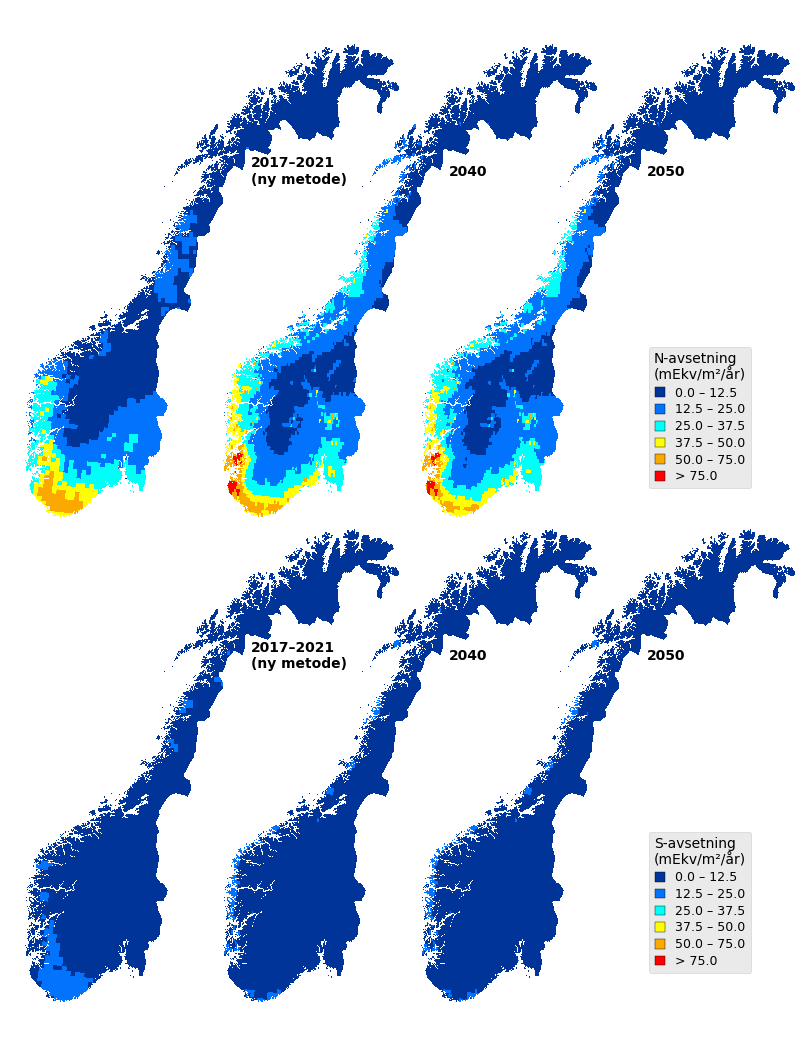

In [3]:
dep_fold = os.path.join(base_path, "deposition")

# Classes for colorbar (mEkv/m²/år)
bounds = [0, 12.5, 25, 37.5, 50, 75, 1e6]
colors = [
    "#003498",  # dark blue
    "#0273FC",  # medium blue
    "#00FFF8",  # light blue
    "#FFFD02",  # yellow
    "#FBA901",  # orange
    "#FE0000",  # red
]
cmap = ListedColormap(colors)
cmap.set_bad((1, 1, 1, 0))  # transparent NaN
norm = BoundaryNorm(bounds, len(colors), clip=True)

fig, axes = plt.subplots(
    nrows=2,
    ncols=3,
    figsize=(11, 11),
)
for row_idx, par in enumerate(["ndep_mgpm2pyr", "sdep_mgpm2pyr"]):
    for col_idx, (short_name, label) in enumerate(names_dict.items()):
        tif_path = os.path.join(
            dep_fold,
            short_name,
            f"{par}_{short_name}_{cell_size}m.tif",
        )
        with rasterio.open(tif_path) as src:
            data = src.read(1).astype(np.float32)
            if src.nodata is not None:
                data[data == src.nodata] = np.nan

            # Convert to mEkv/m²/år
            if par.startswith("n"):
                data = data / 14.0
            else:
                data = data * 2.0 / 32.06

            ax = axes[row_idx, col_idx]
            rasterio.plot.show(
                data,
                ax=ax,
                cmap=cmap,
                norm=norm,
                interpolation="none",
            )
            ax.text(
                0.61,
                0.7,
                label,
                transform=ax.transAxes,
                ha="left",
                va="center",
                fontsize=10,
                fontweight="bold",
            )
            ax.axis("off")

    # Legend for this row
    legend_handles = [
        Patch(
            facecolor=colors[0], edgecolor="black", linewidth=0.3, label="0.0 – 12.5"
        ),
        Patch(
            facecolor=colors[1], edgecolor="black", linewidth=0.3, label="12.5 – 25.0"
        ),
        Patch(
            facecolor=colors[2], edgecolor="black", linewidth=0.3, label="25.0 – 37.5"
        ),
        Patch(
            facecolor=colors[3], edgecolor="black", linewidth=0.3, label="37.5 – 50.0"
        ),
        Patch(
            facecolor=colors[4], edgecolor="black", linewidth=0.3, label="50.0 – 75.0"
        ),
        Patch(facecolor=colors[5], edgecolor="black", linewidth=0.3, label="> 75.0"),
    ]
    title = (
        "N-avsetning\n(mEkv/m²/år)"
        if par.startswith("n")
        else "S-avsetning\n(mEkv/m²/år)"
    )
    axes[row_idx, -1].legend(
        handles=legend_handles,
        title=title,
        loc="lower left",
        bbox_to_anchor=(0.6, 0.1),
        frameon=True,
        fontsize=9,
        title_fontsize=10,
        borderpad=0.4,
        labelspacing=0.3,
        handlelength=0.8,
        handleheight=0.8,
    )
plt.tight_layout()
fig.subplots_adjust(
    left=0.02,
    right=0.98,
    bottom=0.02,
    top=0.95,
    wspace=-0.7,
    hspace=-0.1,
)

# Save
png_path = os.path.join(plot_dir, "deposition.png")
plt.savefig(png_path, dpi=200, bbox_inches="tight")

## 2. Exceedance

SSWC     1721_blrgrid   : mean exceedance = 9.67 mEkv/m²/år
SSWC     bcpred2040     : mean exceedance = 7.45 mEkv/m²/år
SSWC     bcpred2050     : mean exceedance = 7.38 mEkv/m²/år
FAB      1721_blrgrid   : mean exceedance = 22.77 mEkv/m²/år
FAB      bcpred2040     : mean exceedance = 17.21 mEkv/m²/år
FAB      bcpred2050     : mean exceedance = 16.43 mEkv/m²/år


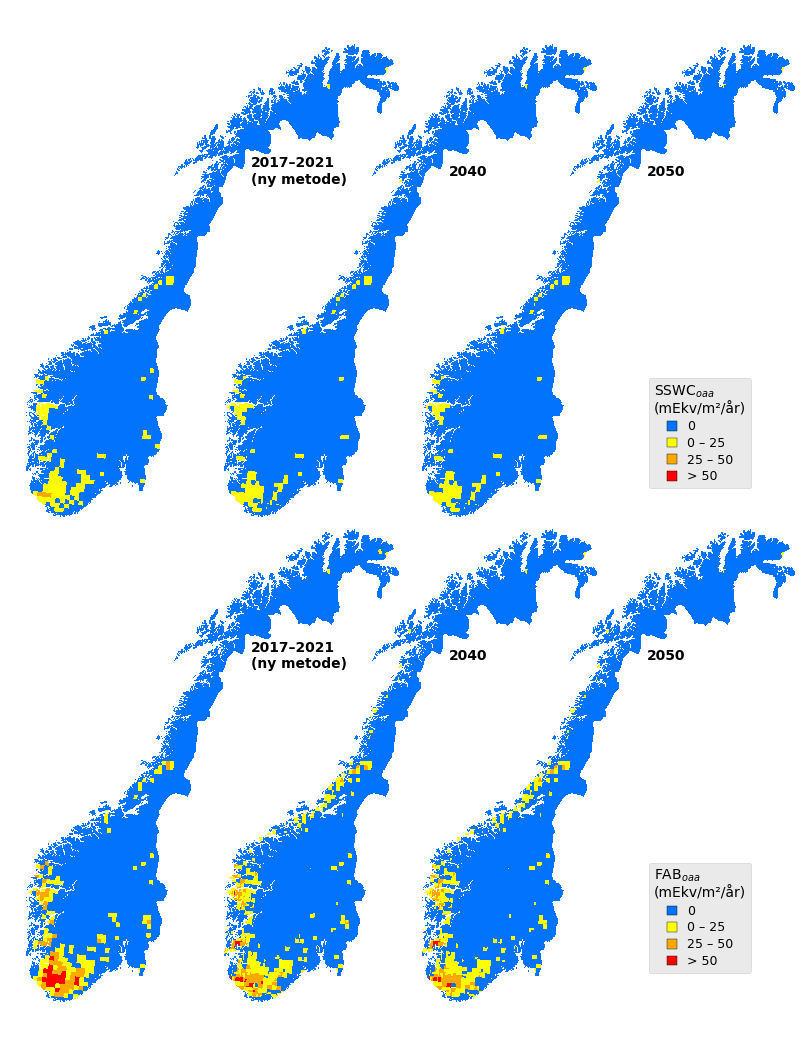

In [4]:
ex_fold = os.path.join(base_path, "exceedance")

# Classes for colorbar (mEkv/m²/år)
eps = np.finfo(np.float32).eps
bounds = [-1e6, eps, 25, 50, 1e6]
colors = [
    "#0273FC",  # medium blue
    "#FFFD02",  # yellow
    "#FBA901",  # orange
    "#FE0000",  # red
]
cmap = ListedColormap(colors)
cmap.set_bad((1, 1, 1, 0))  # transparent NaN
norm = BoundaryNorm(bounds, len(colors), clip=True)

fig, axes = plt.subplots(
    nrows=2,
    ncols=3,
    figsize=(11, 11),
)
for row_idx, par in enumerate(["sswc_ex_meqpm2pyr", "fab_exns_meqpm2pyr"]):
    for col_idx, (short_name, label) in enumerate(names_dict.items()):
        tif_path = os.path.join(
            ex_fold,
            short_name,
            f"{par}_{short_name}_{cell_size}m.tif",
        )

        with rasterio.open(tif_path) as src:
            data = src.read(1).astype(np.float32)
            if src.nodata is not None:
                data[data == src.nodata] = np.nan

            # Print mean exceedance i.e. mean of cells with exceedance > 0
            mean_exceedance = np.nanmean(data[data > 0])
            print(
                f"{par.split('_')[0].upper():8s} {short_name:15s}: "
                f"mean exceedance = {mean_exceedance:.2f} mEkv/m²/år"
            )

            ax = axes[row_idx, col_idx]
            rasterio.plot.show(
                data,
                ax=ax,
                cmap=cmap,
                norm=norm,
                interpolation="none",
            )
            ax.text(
                0.61,
                0.7,
                label,
                transform=ax.transAxes,
                ha="left",
                va="center",
                fontsize=10,
                fontweight="bold",
            )
            ax.axis("off")

    # Legend for this row
    legend_handles = [
        Patch(facecolor=colors[0], edgecolor="black", linewidth=0.3, label="0"),
        Patch(facecolor=colors[1], edgecolor="black", linewidth=0.3, label="0 – 25"),
        Patch(facecolor=colors[2], edgecolor="black", linewidth=0.3, label="25 – 50"),
        Patch(facecolor=colors[3], edgecolor="black", linewidth=0.3, label="> 50"),
    ]
    title = (
        "FAB$_{oaa}$\n(mEkv/m²/år)"
        if par.startswith("f")
        else "SSWC$_{oaa}$\n(mEkv/m²/år)"
    )
    axes[row_idx, -1].legend(
        handles=legend_handles,
        title=title,
        loc="lower left",
        bbox_to_anchor=(0.6, 0.1),
        frameon=True,
        fontsize=9,
        title_fontsize=10,
        borderpad=0.4,
        labelspacing=0.3,
        handlelength=0.8,
        handleheight=0.8,
    )
plt.tight_layout()
fig.subplots_adjust(
    left=0.02,
    right=0.98,
    bottom=0.02,
    top=0.95,
    wspace=-0.7,
    hspace=-0.1,
)

# Save
png_path = os.path.join(plot_dir, "exceedance.png")
plt.savefig(png_path, dpi=200, bbox_inches="tight")